# 03 — EDA: Spatio-Temporal Crime Patterns

**CrimeMapAI | Primary modelling dataset: 2017–2022**

This notebook performs exploratory analysis on the processed district-year panel. It is descriptive: no model is trained here.

### Questions answered
1. How does cyber-crime volume evolve over time?
2. Which states/districts contribute most to reported offences?
3. How skewed and zero-inflated are the crime indicators?
4. Which crime categories move together?
5. How stable is district coverage over time?
6. Are there visible spatial concentration and temporal trend patterns relevant to feature engineering?

**Important:** reported crime is an observed administrative measure, not a direct measure of true underlying crime incidence.


In [31]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = Path("../data/processed")
PANEL_PATH = PROCESSED / "district_year_panel.csv"
MODEL_PATH = PROCESSED / "model_table.csv"

assert PANEL_PATH.exists(), f"Run 02_data_preprocessing.ipynb first: {PANEL_PATH}"

df = pd.read_csv(PANEL_PATH, low_memory=False)
df["year"] = df["year"].astype(int)
print("Panel shape:", df.shape)
print("Years:", sorted(df["year"].unique()))
print("Districts:", df[["state_code", "district_code"]].drop_duplicates().shape[0])


Panel shape: (4347, 46)
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]
Districts: 753


## 1. Coverage and temporal continuity

In [32]:
coverage = (
    df.groupby("year")
      .agg(
          district_years=("district_code", "size"),
          districts=("district_code", "nunique"),
          states=("state_code", "nunique"),
          total_offences=("total_offences_under_ip", "sum"),
          mean_offences=("total_offences_under_ip", "mean"),
          median_offences=("total_offences_under_ip", "median"),
      )
)
coverage


,district_years,districts,states,total_offences,mean_offences,median_offences
year,,,,,,
2017,706,706,36,7976,11.297450,0.0
2018,707,707,36,8647,12.230552,0.0
2019,721,721,36,13730,19.042996,0.0
2020,730,730,36,20201,27.672603,1.0
2021,731,731,36,25384,34.725034,1.0
2022,752,752,36,33786,44.928191,1.0


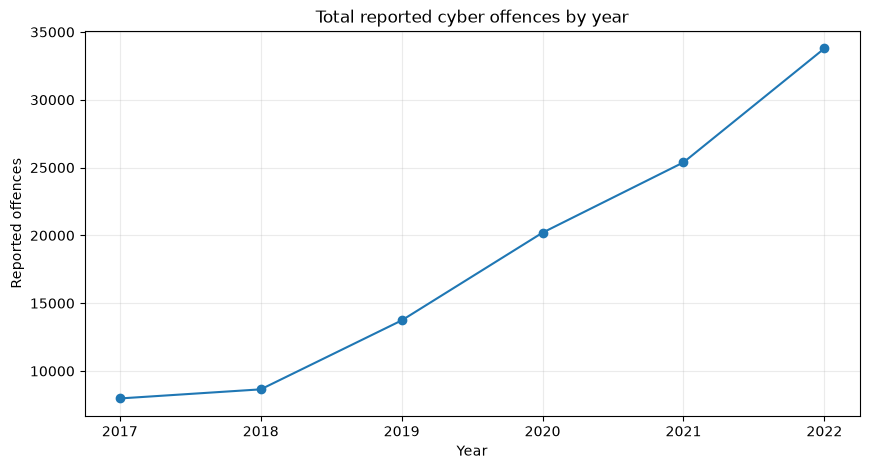

In [33]:
plt.figure(figsize=(10, 5))
plt.plot(coverage.index, coverage["total_offences"], marker="o")
plt.title("Total reported cyber offences by year")
plt.xlabel("Year")
plt.ylabel("Reported offences")
plt.grid(alpha=0.25)
plt.show()


In [34]:
# Districts observed in consecutive years. This is descriptive only; it also helps explain
# why calendar-aware lags are necessary in the preprocessing stage.
year_sets = {y: set(zip(df.loc[df.year == y, "state_code"], df.loc[df.year == y, "district_code"])) for y in sorted(df.year.unique())}
continuity = []
for y in sorted(df.year.unique())[:-1]:
    a, b = year_sets[y], year_sets[y+1]
    continuity.append({"from_year": y, "to_year": y+1, "common_districts": len(a & b), "lost": len(a-b), "new": len(b-a)})
continuity_df = pd.DataFrame(continuity)
continuity_df


,from_year,to_year,common_districts,lost,new
0,2017,2018,706,0,1
1,2018,2019,707,0,14
2,2019,2020,721,0,9
3,2020,2021,730,0,1
4,2021,2022,730,1,22


## 2. State-level distribution

In [35]:
state_year = (
    df.groupby(["year", "state_name"], as_index=False)["total_offences_under_ip"]
      .sum()
)

latest_year = int(df["year"].max())
top_states = (state_year[state_year["year"] == latest_year]
              .sort_values("total_offences_under_ip", ascending=False)
              .head(15))
top_states[["state_name", "total_offences_under_ip"]]


,state_name,total_offences_under_ip
210,Telangana,14933
199,Maharashtra,7482
181,Andhra Pradesh,1922
184,Bihar,1554
204,Odisha,1219
213,Uttar Pradesh,1165
207,Rajasthan,975
189,Gujarat,963
209,Tamil Nadu,593
206,Punjab,425


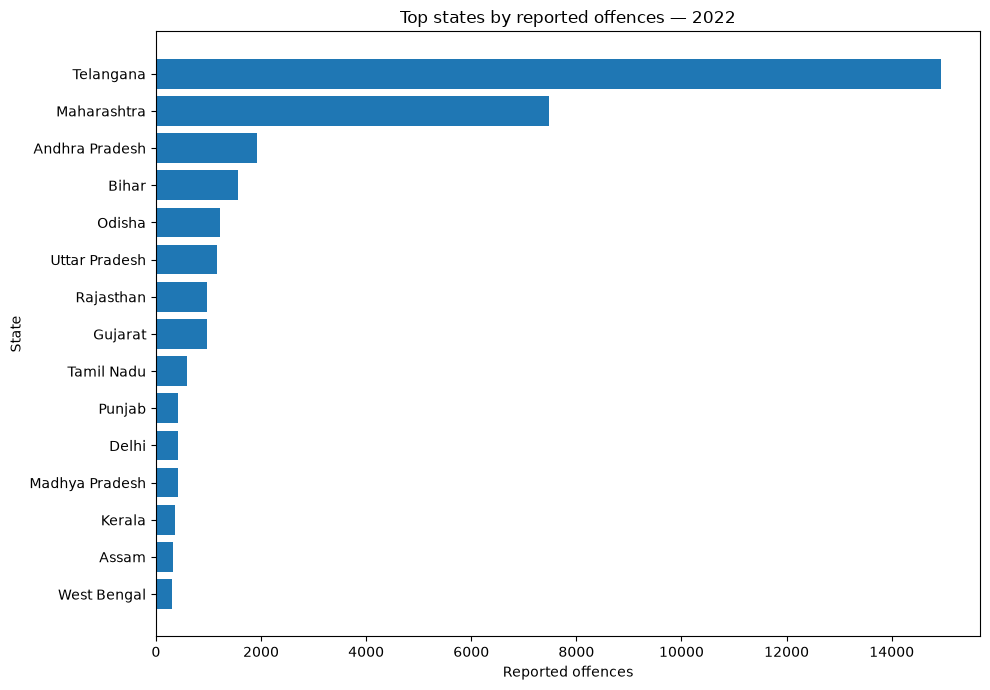

In [36]:
plt.figure(figsize=(10, 7))
plot_df = top_states.sort_values("total_offences_under_ip")
plt.barh(plot_df["state_name"], plot_df["total_offences_under_ip"])
plt.title(f"Top states by reported offences — {latest_year}")
plt.xlabel("Reported offences")
plt.ylabel("State")
plt.tight_layout()
plt.show()


## 3. District concentration and hotspot descriptives

In [37]:
latest = df[df["year"] == latest_year].copy()
top_districts = (
    latest[["state_name", "district_name", "total_offences_under_ip"]]
    .sort_values("total_offences_under_ip", ascending=False)
    .head(20)
)
top_districts


,state_name,district_name,total_offences_under_ip
4200,Telangana,Ranga Reddy,5395
3417,Maharashtra,Mumbai,4716
4158,Telangana,Hyderabad,4151
4296,Telangana,Yadadri Bhuvanagiri,2180
971,Uttar Pradesh,Gautam Buddha Nagar,755
4206,Telangana,Warangal,630
3597,Andhra Pradesh,Visakhapatnam,583
3507,Maharashtra,Thane,500
3465,Maharashtra,Pune,448
1408,Bihar,Patna,362


In [38]:
# Concentration of reported offences among the top districts.
sorted_values = np.sort(latest["total_offences_under_ip"].to_numpy())[::-1]
for k in [5, 10, 20, 50]:
    share = sorted_values[:k].sum() / sorted_values.sum() if sorted_values.sum() else np.nan
    print(f"Top {k} districts share: {share:.2%}")


Top 5 districts share: 50.90%
Top 10 districts share: 58.37%
Top 20 districts share: 65.93%
Top 50 districts share: 76.04%


## 4. Distribution, skewness, and zero inflation

In [39]:
META = {"id", "year", "state_name", "state_code", "district_name", "district_code", "registration_circles"}
crime_cols = [c for c in df.columns if c not in META and pd.api.types.is_numeric_dtype(df[c])]

dist_summary = pd.DataFrame({
    "zero_share": (df[crime_cols] == 0).mean(),
    "mean": df[crime_cols].mean(),
    "median": df[crime_cols].median(),
    "max": df[crime_cols].max(),
    "skew": df[crime_cols].skew(),
}).sort_values("zero_share", ascending=False)
dist_summary.head(20)


,zero_share,mean,median,max,skew
stamps_counterfeiting,1.000000,0.000000,0.0,0,0.000000
un_athryz_access_atmpt_access_prct_comp_sys,0.998160,0.002300,0.0,2,27.646315
trade_marks_act,0.997700,0.007131,0.0,14,49.068577
abetment_to_commit_offences,0.997700,0.002991,0.0,3,29.422981
interception_or_monitoring_or_decryption_of_info,0.997239,0.006671,0.0,7,31.709544
lotteries_act,0.996549,0.013343,0.0,18,39.887059
currency_counterfeiting,0.996319,0.004831,0.0,4,28.391859
attempt_to_commit_offences,0.990108,0.016563,0.0,11,29.418300
abetment_of_suicide_online,0.988728,0.013573,0.0,3,11.728992
cyber_terrorism,0.986197,0.022774,0.0,8,18.423787


In [40]:
# Show the most prevalent non-zero / high-volume indicators without treating IQR flags as data errors.
summary_nonzero = dist_summary.sort_values("mean", ascending=False).head(15)
summary_nonzero


,zero_share,mean,median,max,skew
total_offences_under_ip,0.515528,25.241316,0.0,5395,20.120382
cheating_by_personation_by_using_computer_resource,0.685530,10.719117,0.0,6519,35.339776
identity_theft,0.692202,8.654934,0.0,10002,43.019402
cheating,0.800322,6.595583,0.0,3538,30.542279
offences_other_than_ransom_ware,0.821026,4.428111,0.0,1087,20.558898
online_banking_fraud,0.823556,4.422820,0.0,2456,34.951129
other_offences,0.747872,2.906142,0.0,580,19.080036
pub_or_trans_obscene_material_in_electronic_form,0.707154,2.886818,0.0,303,10.938342
other_frauds,0.873706,2.822176,0.0,1222,26.469839
atms_fraud,0.817115,2.448355,0.0,276,12.242309


## 5. Crime-category relationships

In [41]:
# Correlation is exploratory only. Spearman is more appropriate for skewed count variables.
from scipy.stats import spearmanr

rank_cols = crime_cols.copy()
rank_corr = df[rank_cols].corr(method="spearman")
rank_corr.shape


(41, 41)

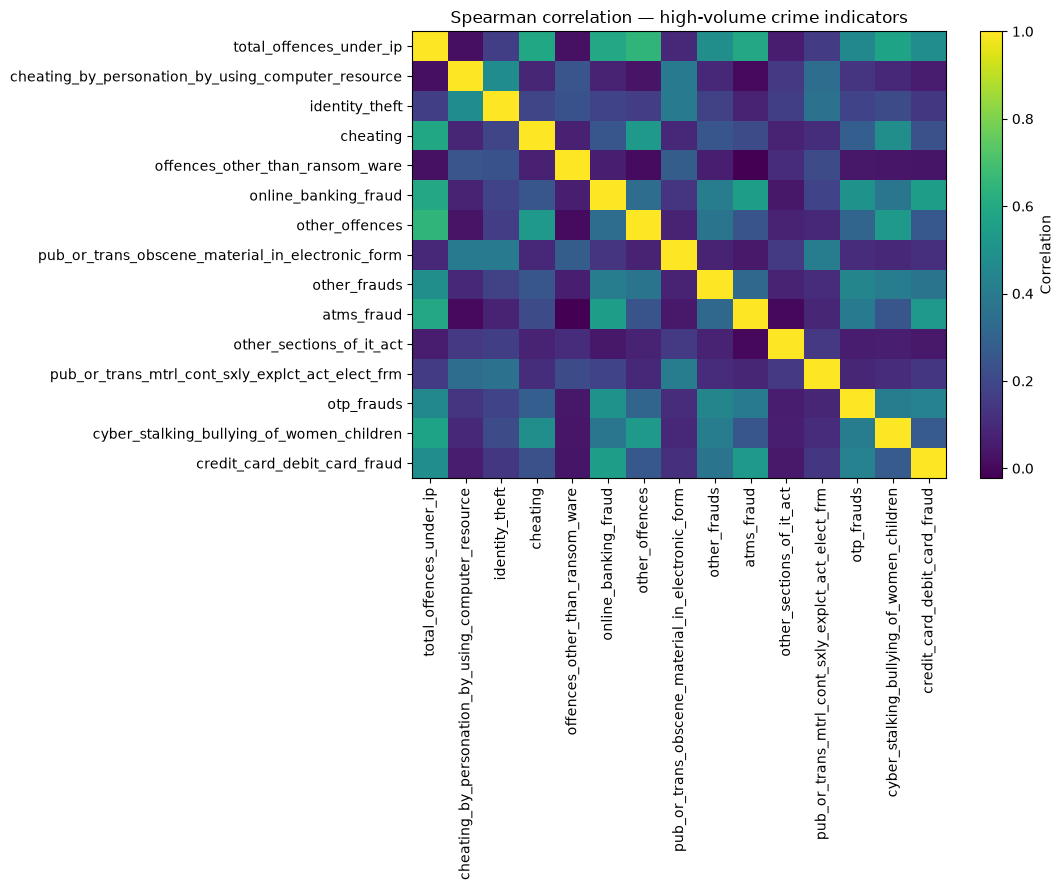

In [42]:
# Compact heatmap for the 15 highest-mean indicators.
selected = dist_summary.sort_values("mean", ascending=False).head(15).index.tolist()
plt.figure(figsize=(11, 9))
plt.imshow(rank_corr.loc[selected, selected], aspect="auto")
plt.xticks(range(len(selected)), selected, rotation=90)
plt.yticks(range(len(selected)), selected)
plt.title("Spearman correlation — high-volume crime indicators")
plt.colorbar(label="Correlation")
plt.tight_layout()
plt.show()


## 6. Year-over-year target dynamics

In [43]:
target_year = coverage[["total_offences", "mean_offences", "median_offences"]].copy()
target_year["YoY_change"] = target_year["total_offences"].diff()
target_year["YoY_growth"] = target_year["total_offences"].pct_change()
target_year


,total_offences,mean_offences,median_offences,YoY_change,YoY_growth
year,,,,,
2017,7976,11.297450,0.0,NaN,NaN
2018,8647,12.230552,0.0,671.0,0.084127
2019,13730,19.042996,0.0,5083.0,0.587834
2020,20201,27.672603,1.0,6471.0,0.471304
2021,25384,34.725034,1.0,5183.0,0.256571
2022,33786,44.928191,1.0,8402.0,0.330996


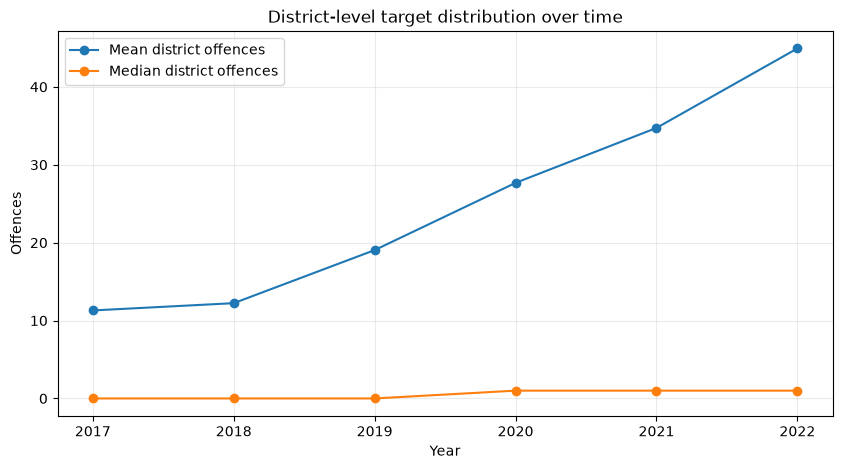

In [44]:
plt.figure(figsize=(10, 5))
plt.plot(target_year.index, target_year["mean_offences"], marker="o", label="Mean district offences")
plt.plot(target_year.index, target_year["median_offences"], marker="o", label="Median district offences")
plt.title("District-level target distribution over time")
plt.xlabel("Year")
plt.ylabel("Offences")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 7. EDA conclusions to carry into modelling

In [45]:
eda_findings = {
    "coverage": coverage.to_dict(),
    "top_states_latest_year": top_states.to_dict("records"),
    "top_districts_latest_year": top_districts.to_dict("records"),
    "most_zero_inflated": dist_summary.head(10)[["zero_share", "mean", "median", "max", "skew"]].to_dict("index"),
}

print("EDA artifact assembled. Record the substantive findings in progress.md after reviewing the plots.")


EDA artifact assembled. Record the substantive findings in progress.md after reviewing the plots.


### Interpretation discipline

Do not interpret high reported counts as proof that an area is intrinsically more criminal or that observed differences are causal. The dashboard and report should frame these results as patterns in reported/recorded cyber-crime data.
